# Smart Traffic Intelligence System
## Phase 3: Exploratory Data Analysis (EDA)

### Objectives
1. Analyze accident severity distribution.
2. Identify accident patterns by hour and weekday.
3. Analyze accidents across boroughs.
4. Identify frequently reported contributing factors.
5. Analyze injury and fatality patterns.
6. Explore geographical accident distribution.
7. Generate visualizations for further analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")

print("EDA libraries imported successfully!")

EDA libraries imported successfully!


In [2]:
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "dataset").exists():
    PROJECT_DIR = PROJECT_DIR.parent

CLEANED_PATH = (
    PROJECT_DIR / "dataset" / "processed" / "cleaned_accidents.csv"
)

CHART_DIR = PROJECT_DIR / "visualizations" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Cleaned dataset:", CLEANED_PATH)
print("File exists:", CLEANED_PATH.exists())

if not CLEANED_PATH.exists():
    raise FileNotFoundError(
        "cleaned_accidents.csv was not found. "
        "Run the final save cell in 02_data_cleaning.ipynb first."
    )

# Read the column names first
available_columns = pd.read_csv(CLEANED_PATH, nrows=0).columns.tolist()

# Load only the columns needed for EDA
preferred_columns = [
    "collision_id",
    "crash_date",
    "crash_time",
    "borough",
    "latitude",
    "longitude",
    "number_of_persons_injured",
    "number_of_persons_killed",
    "contributing_factor_vehicle_1",
    "vehicle_type_code_1",
    "accident_severity",
    "crash_hour",
    "day_of_week",
    "month",
    "year",
    "is_weekend",
    "time_period",
    "total_persons_affected"
]

selected_columns = [
    col for col in preferred_columns
    if col in available_columns
]

eda_df = pd.read_csv(
    CLEANED_PATH,
    usecols=selected_columns,
    low_memory=False
)

print("\nEDA dataset loaded successfully!")
print("Dataset shape:", eda_df.shape)
display(eda_df.head())

Project directory: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project
Cleaned dataset: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\dataset\processed\cleaned_accidents.csv
File exists: True

EDA dataset loaded successfully!
Dataset shape: (2301644, 18)


,crash_date,crash_time,borough,latitude,longitude,number_of_persons_injured,number_of_persons_killed,contributing_factor_vehicle_1,collision_id,vehicle_type_code_1,accident_severity,crash_hour,day_of_week,month,year,is_weekend,time_period,total_persons_affected
0,2026-10-27,15:48,MANHATTAN,40.720448,-74.005590,0.0,0.0,Does Not Apply,73fa239b448001d1b74e285a42d70488,4 dr sedan,Property Damage Only,15,Tuesday,10,2026,False,Afternoon,0.0
1,2026-10-27,23:54,BROOKLYN,40.641815,-73.995810,0.0,0.0,Does Not Apply,1ca9703d3d16fae179d917b36065331a,Station Wagon/Sport Utility Vehicle,Property Damage Only,23,Tuesday,10,2026,False,Night,0.0
2,2026-10-27,12:35,QUEENS,40.704185,-73.785980,2.0,0.0,Driver Inattention/Distraction,005e53cae38738ee5bbedf0da83662f1,4 dr sedan,Injury,12,Tuesday,10,2026,False,Afternoon,2.0
3,2026-10-27,07:35,BRONX,NaN,NaN,0.0,0.0,Does Not Apply,ca38ea795663bff25cf2728441997fbe,4 dr sedan,Property Damage Only,7,Tuesday,10,2026,False,Morning,0.0
4,2026-10-27,15:53,MANHATTAN,40.860910,-73.921524,0.0,0.0,Does Not Apply,d803d9ca816ccde76301f0bad3b8b5e5,Bus (Omnibus),Property Damage Only,15,Tuesday,10,2026,False,Afternoon,0.0


In [3]:
# Convert date and time
if "crash_date" in eda_df.columns:
    eda_df["crash_date"] = pd.to_datetime(
        eda_df["crash_date"], errors="coerce"
    )

if "crash_time" in eda_df.columns:
    eda_df["crash_time"] = eda_df["crash_time"].astype("string").str.strip()

    parsed_time = pd.to_datetime(
        eda_df["crash_time"],
        format="%H:%M",
        errors="coerce"
    )

    eda_df["crash_hour"] = parsed_time.dt.hour

# Convert numeric fields
numeric_columns = [
    "latitude",
    "longitude",
    "number_of_persons_injured",
    "number_of_persons_killed",
    "crash_hour"
]

for col in numeric_columns:
    if col in eda_df.columns:
        eda_df[col] = pd.to_numeric(
            eda_df[col], errors="coerce"
        )

# Create missing time features if necessary
if "crash_date" in eda_df.columns:
    if "day_of_week" not in eda_df.columns:
        eda_df["day_of_week"] = eda_df["crash_date"].dt.day_name()

    if "month" not in eda_df.columns:
        eda_df["month"] = eda_df["crash_date"].dt.month

    if "year" not in eda_df.columns:
        eda_df["year"] = eda_df["crash_date"].dt.year

if "accident_severity" not in eda_df.columns:
    raise ValueError(
        "accident_severity is missing. Check the Phase 2 output."
    )

print("EDA preparation completed!")
print("Available columns:", eda_df.columns.tolist())

EDA preparation completed!
Available columns: ['crash_date', 'crash_time', 'borough', 'latitude', 'longitude', 'number_of_persons_injured', 'number_of_persons_killed', 'contributing_factor_vehicle_1', 'collision_id', 'vehicle_type_code_1', 'accident_severity', 'crash_hour', 'day_of_week', 'month', 'year', 'is_weekend', 'time_period', 'total_persons_affected']


In [4]:
total_accidents = len(eda_df)

total_injured = (
    eda_df["number_of_persons_injured"].fillna(0).sum()
    if "number_of_persons_injured" in eda_df.columns else 0
)

total_fatalities = (
    eda_df["number_of_persons_killed"].fillna(0).sum()
    if "number_of_persons_killed" in eda_df.columns else 0
)

summary = pd.DataFrame({
    "Metric": [
        "Total Accident Records",
        "Total Persons Injured",
        "Total Persons Killed",
        "Unique Boroughs",
        "Records with Valid Coordinates"
    ],
    "Value": [
        total_accidents,
        int(total_injured),
        int(total_fatalities),
        eda_df["borough"].nunique()
        if "borough" in eda_df.columns else np.nan,
        (
            eda_df["latitude"].notna()
            & eda_df["longitude"].notna()
        ).sum()
        if {"latitude", "longitude"}.issubset(eda_df.columns)
        else np.nan
    ]
})

print("OVERALL ACCIDENT STATISTICS")
display(summary)

OVERALL ACCIDENT STATISTICS


,Metric,Value
0,Total Accident Records,2301644
1,Total Persons Injured,776979
2,Total Persons Killed,3737
3,Unique Boroughs,6
4,Records with Valid Coordinates,2060910


,Accident Count,Percentage
accident_severity,,
Property Damage Only,1725037,74.95
Injury,573026,24.90
Fatal,3581,0.16


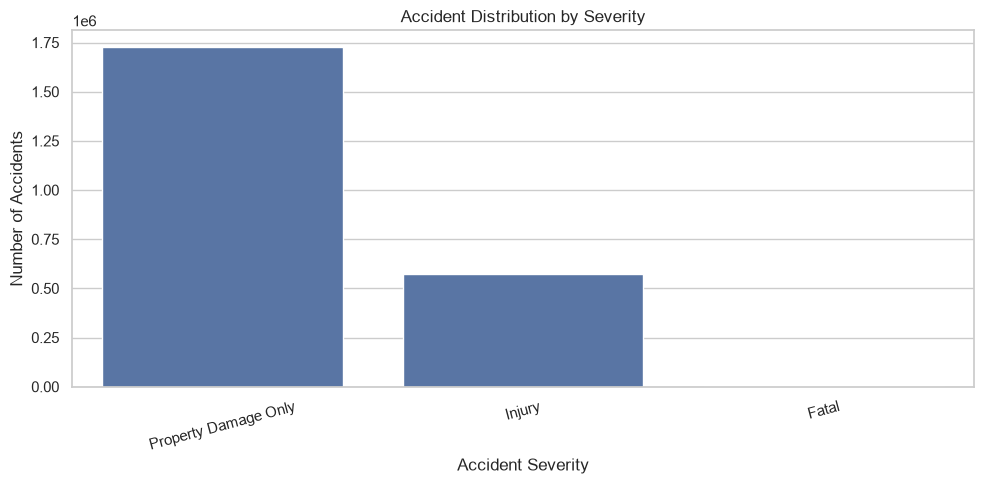

In [5]:
severity_counts = (
    eda_df["accident_severity"]
    .value_counts()
    .reindex(
        ["Property Damage Only", "Injury", "Fatal"],
        fill_value=0
    )
)

severity_percentages = (
    severity_counts / severity_counts.sum() * 100
).round(2)

severity_report = pd.DataFrame({
    "Accident Count": severity_counts,
    "Percentage": severity_percentages
})

display(severity_report)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=severity_report.index,
    y=severity_report["Accident Count"]
)

plt.title("Accident Distribution by Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "accident_severity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

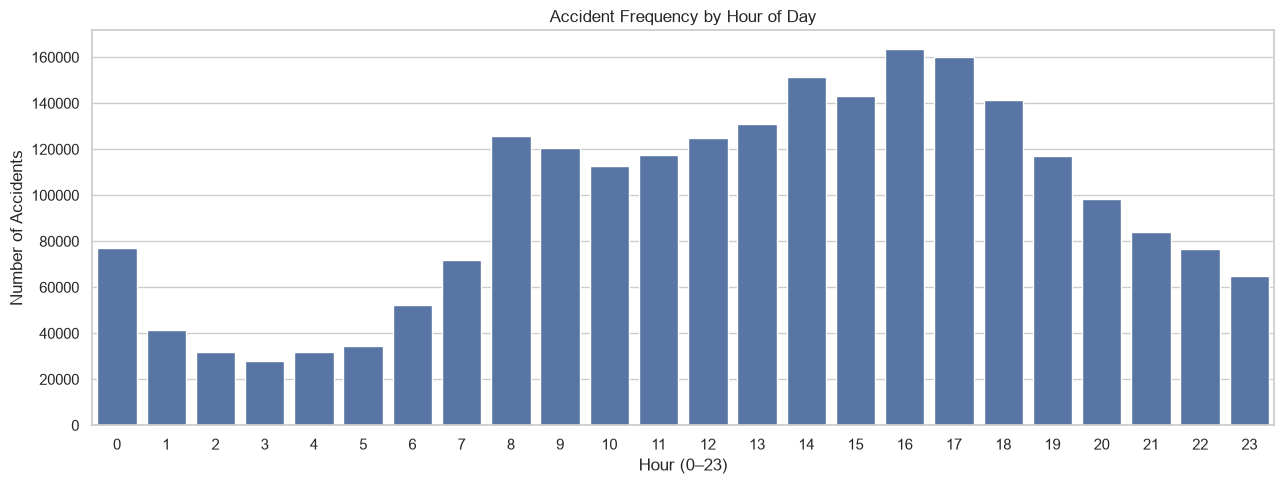

Highest accident-count hour: 16


In [6]:
if "crash_hour" in eda_df.columns:
    hourly_counts = (
        eda_df["crash_hour"]
        .dropna()
        .astype(int)
        .value_counts()
        .reindex(range(24), fill_value=0)
        .sort_index()
    )

    plt.figure(figsize=(13, 5))
    sns.barplot(
        x=hourly_counts.index,
        y=hourly_counts.values
    )

    plt.title("Accident Frequency by Hour of Day")
    plt.xlabel("Hour (0–23)")
    plt.ylabel("Number of Accidents")
    plt.xticks(range(24))
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "accidents_by_hour.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    print("Highest accident-count hour:", hourly_counts.idxmax())
else:
    print("Crash hour is unavailable.")

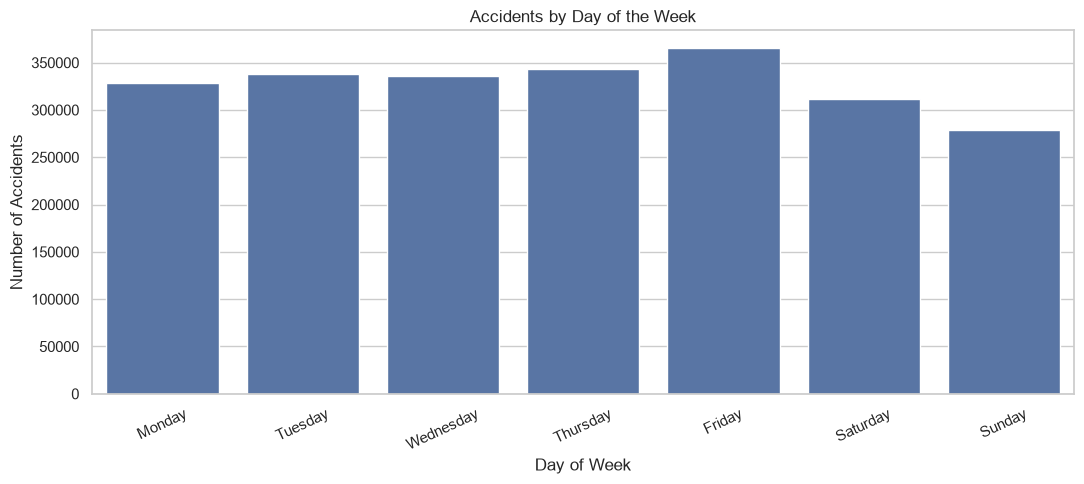

Highest accident-count weekday: Friday


In [7]:
if "day_of_week" in eda_df.columns:
    weekday_order = [
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ]

    weekday_counts = (
        eda_df["day_of_week"]
        .value_counts()
        .reindex(weekday_order, fill_value=0)
    )

    plt.figure(figsize=(11, 5))
    sns.barplot(
        x=weekday_counts.index,
        y=weekday_counts.values
    )

    plt.title("Accidents by Day of the Week")
    plt.xlabel("Day of Week")
    plt.ylabel("Number of Accidents")
    plt.xticks(rotation=25)
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "accidents_by_weekday.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    print("Highest accident-count weekday:", weekday_counts.idxmax())
else:
    print("Day of week is unavailable.")

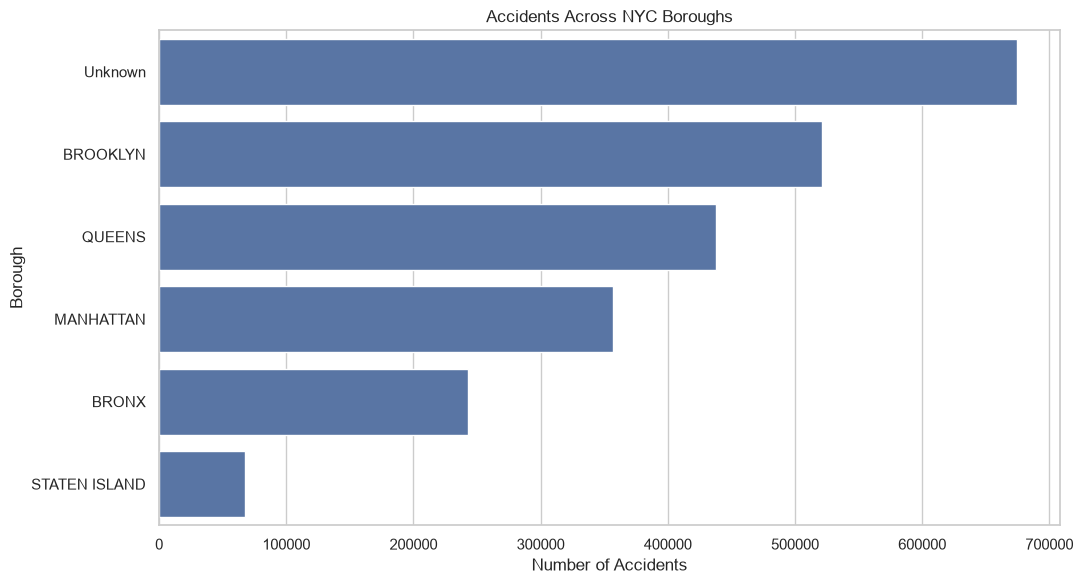

,Accident Count
borough,
Unknown,674813
BROOKLYN,521523
QUEENS,437708
MANHATTAN,356888
BRONX,242904
STATEN ISLAND,67808


In [8]:
if "borough" in eda_df.columns:
    borough_counts = (
        eda_df["borough"]
        .fillna("Unknown")
        .str.strip()
        .replace("", "Unknown")
        .value_counts()
    )

    plt.figure(figsize=(11, 6))
    sns.barplot(
        x=borough_counts.values,
        y=borough_counts.index
    )

    plt.title("Accidents Across NYC Boroughs")
    plt.xlabel("Number of Accidents")
    plt.ylabel("Borough")
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "accidents_by_borough.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    display(borough_counts.to_frame("Accident Count"))
else:
    print("Borough column is unavailable.")

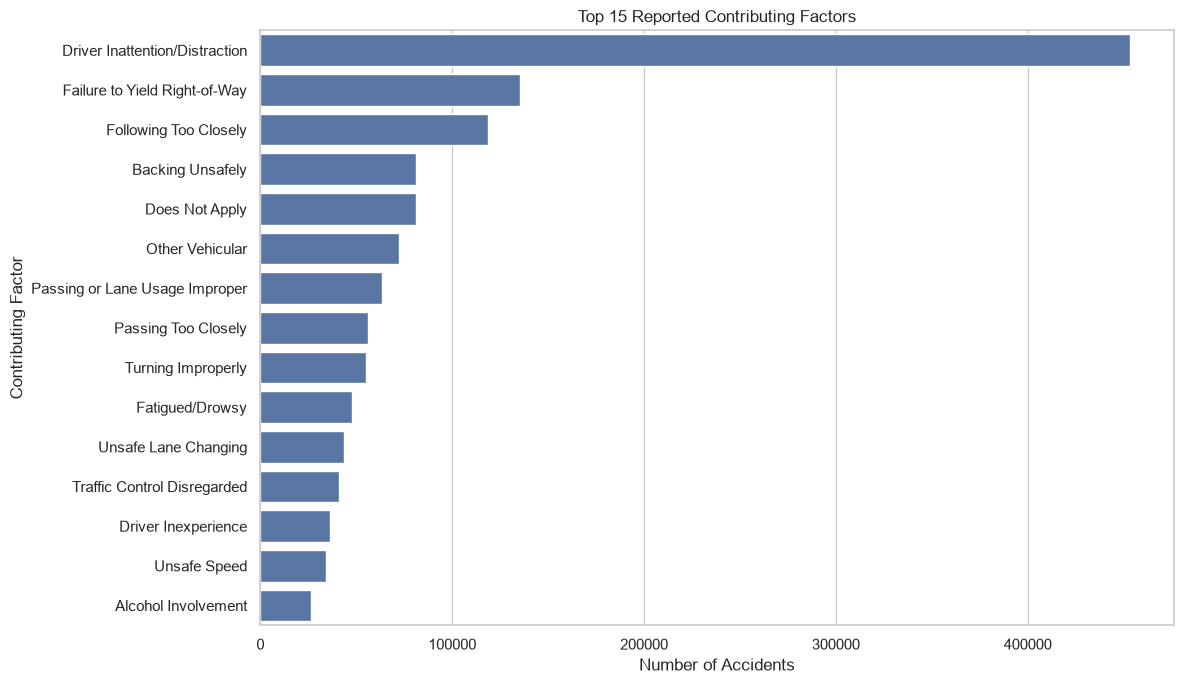

,Accident Count
contributing_factor_vehicle_1,
Driver Inattention/Distraction,453543
Failure to Yield Right-of-Way,135268
Following Too Closely,118553
Backing Unsafely,81161
Does Not Apply,80859
Other Vehicular,72289
Passing or Lane Usage Improper,63419
Passing Too Closely,56276
Turning Improperly,54803


In [9]:
factor_column = "contributing_factor_vehicle_1"

if factor_column in eda_df.columns:
    factors = (
        eda_df[factor_column]
        .dropna()
        .astype(str)
        .str.strip()
    )

    factors = factors[
        (factors != "")
        & (factors.str.lower() != "unspecified")
    ]

    top_factors = factors.value_counts().head(15)

    plt.figure(figsize=(12, 7))
    sns.barplot(
        x=top_factors.values,
        y=top_factors.index
    )

    plt.title("Top 15 Reported Contributing Factors")
    plt.xlabel("Number of Accidents")
    plt.ylabel("Contributing Factor")
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "top_contributing_factors.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    display(top_factors.to_frame("Accident Count"))
else:
    print("Contributing factor column is unavailable.")

,Accident_Count,Total_Injuries,Total_Fatalities
borough,,,
Unknown,674813,243352.0,1361.0
BROOKLYN,521523,190069.0,779.0
QUEENS,437708,147002.0,668.0
MANHATTAN,356888,86060.0,441.0
BRONX,242904,89401.0,373.0
STATEN ISLAND,67808,21095.0,115.0


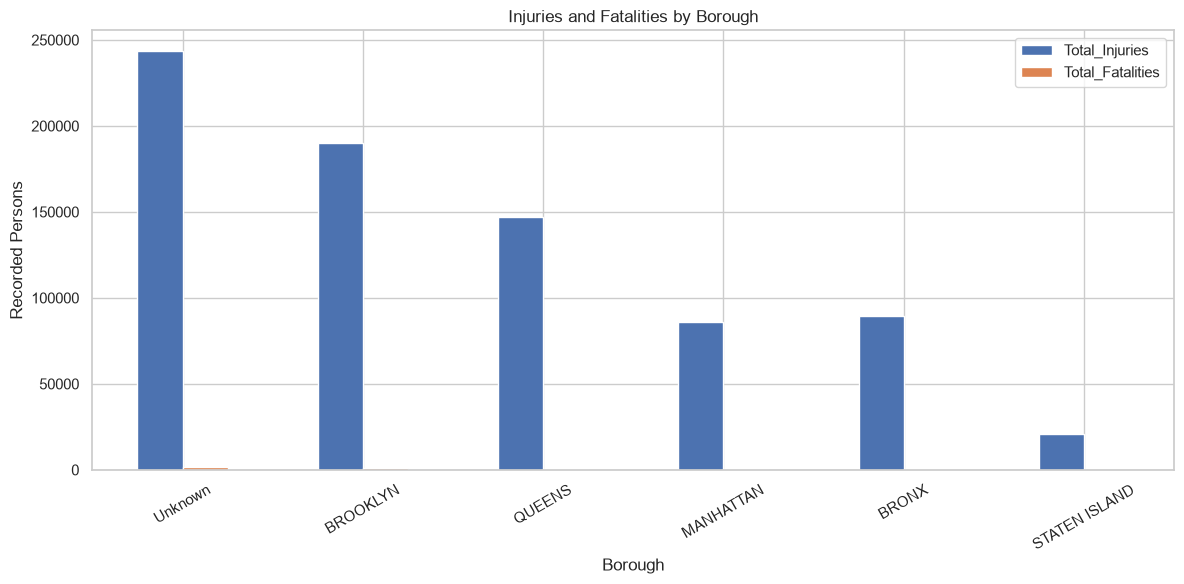

In [10]:
required = {
    "borough",
    "number_of_persons_injured",
    "number_of_persons_killed"
}

if required.issubset(eda_df.columns):
    borough_impact = (
        eda_df.groupby("borough", dropna=False)
        .agg(
            Accident_Count=("borough", "size"),
            Total_Injuries=("number_of_persons_injured", "sum"),
            Total_Fatalities=("number_of_persons_killed", "sum")
        )
        .sort_values("Accident_Count", ascending=False)
    )

    display(borough_impact)

    borough_impact[
        ["Total_Injuries", "Total_Fatalities"]
    ].plot(
        kind="bar",
        figsize=(12, 6)
    )

    plt.title("Injuries and Fatalities by Borough")
    plt.xlabel("Borough")
    plt.ylabel("Recorded Persons")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "borough_injury_fatality_analysis.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("Required borough/injury/fatality columns are unavailable.")

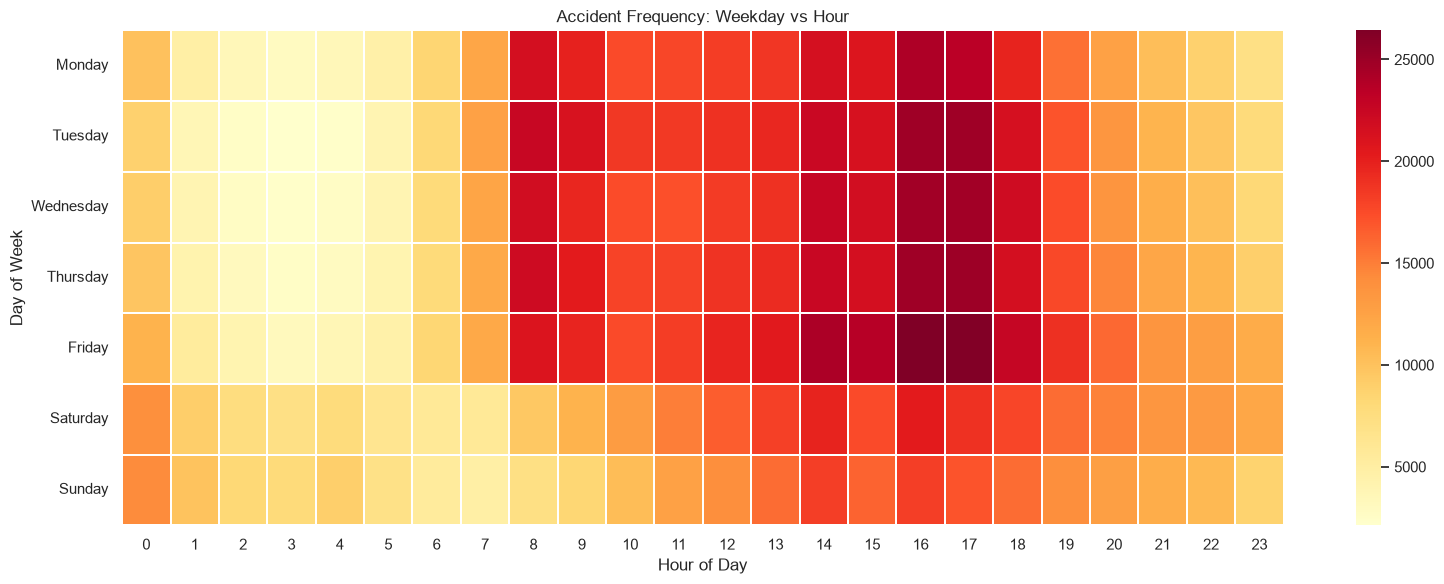

In [11]:
if {"day_of_week", "crash_hour"}.issubset(eda_df.columns):
    weekday_order = [
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ]

    heatmap_data = eda_df.dropna(
        subset=["day_of_week", "crash_hour"]
    ).copy()

    heatmap_data["crash_hour"] = (
        heatmap_data["crash_hour"].astype(int)
    )

    heatmap_table = pd.crosstab(
        heatmap_data["day_of_week"],
        heatmap_data["crash_hour"]
    ).reindex(
        index=weekday_order,
        columns=range(24),
        fill_value=0
    )

    plt.figure(figsize=(16, 6))
    sns.heatmap(
        heatmap_table,
        cmap="YlOrRd",
        linewidths=0.2
    )

    plt.title("Accident Frequency: Weekday vs Hour")
    plt.xlabel("Hour of Day")
    plt.ylabel("Day of Week")
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "weekday_hour_heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("Weekday or crash-hour information is unavailable.")

In [16]:
import pandas as pd
import plotly.express as px
from pathlib import Path

# Check geographical data
if "geo_df" not in globals() or geo_df.empty:
    raise ValueError("Please run the geographical validation cell first.")

# Select sample records
map_sample = geo_df.sample(
    n=min(3000, len(geo_df)),
    random_state=42
).copy()

# Create interactive map using scatter_map
fig = px.scatter_map(
    map_sample,
    lat="latitude",
    lon="longitude",
    hover_name="borough" if "borough" in map_sample.columns else None,
    zoom=9,
    height=650,
    title="NYC Motor Vehicle Accident Locations",
)

# Customize accident markers
fig.update_traces(
    marker=dict(
        size=8,
        color="red",
        opacity=0.7
    )
)

# Center the map
fig.update_layout(
    map_style="open-street-map",
    map_center={
        "lat": map_sample["latitude"].median(),
        "lon": map_sample["longitude"].median()
    },
    margin=dict(l=0, r=0, t=50, b=0)
)

# Save interactive map
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "visualizations").exists():
    PROJECT_DIR = PROJECT_DIR.parent

map_folder = PROJECT_DIR / "visualizations" / "maps"
map_folder.mkdir(parents=True, exist_ok=True)

map_file = map_folder / "accident_distribution_map.html"

fig.write_html(
    str(map_file),
    include_plotlyjs=True,
    full_html=True
)

print("Map generated successfully!")
print("Total valid records:", len(geo_df))
print("Accident points displayed:", len(map_sample))
print("Map saved at:", map_file)

Map generated successfully!
Total valid records: 2052391
Accident points displayed: 3000
Map saved at: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\visualizations\maps\accident_distribution_map.html


In [17]:
# ==========================================
# PHASE 3: FINAL EDA SUMMARY
# ==========================================

print("=" * 60)
print("SMART TRAFFIC INTELLIGENCE SYSTEM")
print("PHASE 3: EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 60)

print("\n1. DATASET INFORMATION")

print("Total accident records:", len(eda_df))
print("Total columns:", len(eda_df.columns))

print("\n2. DATE INFORMATION")

if "crash_date" in eda_df.columns:
    print("First date:", eda_df["crash_date"].min())
    print("Last date:", eda_df["crash_date"].max())

print("\n3. MISSING VALUES")

print("Total missing values:", eda_df.isnull().sum().sum())

print("\n4. GEOGRAPHICAL INFORMATION")

if "geo_df" in globals():
    print("Valid geographical records:", len(geo_df))
else:
    print("Geographical dataframe not available.")

print("\n5. ACCIDENT INJURY INFORMATION")

if "number_of_persons_injured" in eda_df.columns:
    print(
        "Total recorded injuries:",
        pd.to_numeric(
            eda_df["number_of_persons_injured"],
            errors="coerce"
        ).sum()
    )

if "number_of_persons_killed" in eda_df.columns:
    print(
        "Total recorded fatalities:",
        pd.to_numeric(
            eda_df["number_of_persons_killed"],
            errors="coerce"
        ).sum()
    )

print("\n6. OUTPUT FILES")

print("Accident distribution map:")
print(PROJECT_DIR / "visualizations" / "maps" / "accident_distribution_map.html")

print("\n" + "=" * 60)
print("PHASE 3 EDA COMPLETED SUCCESSFULLY")
print("=" * 60)

SMART TRAFFIC INTELLIGENCE SYSTEM
PHASE 3: EXPLORATORY DATA ANALYSIS SUMMARY

1. DATASET INFORMATION
Total accident records: 2301644
Total columns: 18

2. DATE INFORMATION
First date: 2012-07-01 00:00:00
Last date: 2026-10-27 00:00:00

3. MISSING VALUES
Total missing values: 481468

4. GEOGRAPHICAL INFORMATION
Valid geographical records: 2052391

5. ACCIDENT INJURY INFORMATION
Total recorded injuries: 776979.0
Total recorded fatalities: 3737.0

6. OUTPUT FILES
Accident distribution map:
c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\visualizations\maps\accident_distribution_map.html

PHASE 3 EDA COMPLETED SUCCESSFULLY
